# Mandatory assignment 3

**GitHub repository:** https://github.com/Israt0408/TECH2-H26_IM_assignment3.git

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

In [15]:
#Loading data
import pandas as pd

file='SCF_10pct.csv'
df= pd.read_csv(file)
df.isna().sum()

id         0
year       0
age        0
educ      16
stocks    18
equity    16
dtype: int64

In [16]:
#dropping that have missing values
columns=['id', 'year', 'age', 'educ', 'stocks', 'equity']
for i in range(len(columns)):
    rows_before_drop=len(df)
    df=df.dropna(subset=[columns[i]])
    rows_after_drop=len(df)
    drop= rows_before_drop-rows_after_drop
    print(f'{columns[i]}: drop {drop} and remaining {rows_after_drop} rows')

id: drop 0 and remaining 5808 rows
year: drop 0 and remaining 5808 rows
age: drop 0 and remaining 5808 rows
educ: drop 16 and remaining 5792 rows
stocks: drop 18 and remaining 5774 rows
equity: drop 16 and remaining 5758 rows


In [17]:
#keeping observant from age 25 to 89
row_before= len(df)

df=df[(df['age']>=25) & (df['age']<=89)]
row_now = len(df)
dropped= row_before-row_now
print(f'The age restriction dropped {dropped} and {row_now} rows remained')

The age restriction dropped 326 and 5432 rows remained


In [18]:
df['direct']= (df['stocks']>0).astype(int)
df['overall']= (df['equity']>0).astype(int)
df

,id,year,age,educ,stocks,equity,direct,overall
0,0,1989,35,2.0,0.0,0.0,0,0
1,1,1989,33,2.0,0.0,0.0,0,0
2,2,1989,62,1.0,0.0,0.0,0,0
4,4,1989,70,1.0,0.0,0.0,0,0
5,5,1989,50,1.0,0.0,0.0,0,0
...,...,...,...,...,...,...,...,...
5802,5802,2022,77,3.0,0.0,0.0,0,0
5804,5804,2022,33,3.0,0.0,0.0,0,0
5805,5805,2022,81,2.0,100000.0,100000.0,1,1
5806,5806,2022,58,3.0,40000.0,1212000.0,1,1


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

In [19]:
#making the function
def participation_rate(indicator):
    count=0
    for i in indicator:
        count=count+i
    rate= count/len(indicator) *100
    return rate

In [20]:
#computing direct and overall column
direct= participation_rate(df['direct'])
overall= participation_rate(df['overall'])
print(f'Direct participation rate is {direct:.1f}%')
print(f'Overall participation rate is {overall:.1f}%')


Direct participation rate is 17.0%
Overall participation rate is 49.4%


In [21]:
#Using pandas to calculate mean

direct_rate=df['direct'].mean()*100
overall_rate=df['overall'].mean()*100
#direct_rate= x*100
#overall_rate= y*100
print(f'Direct participation rate is {direct_rate:.1f}%')
print(f'Overall participation rate is {overall_rate:.1f}%')


Direct participation rate is 17.0%
Overall participation rate is 49.4%


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

In [22]:

#looping over each educ category and displaying to 1 decimal
direct_list=[]
overall_list=[]
for level in range(1,5):
    group=df[df['educ']==level]
    direct_rate= participation_rate(group['direct'])
    direct_list.append(direct_rate)
    overall_rate= participation_rate(group['overall'])
    overall_list.append(overall_rate)
    print(f'Education level {level}, direct {direct_rate:.1f}% and overall {overall_rate:.1f}%')


Education level 1, direct 4.4% and overall 17.3%
Education level 2, direct 11.4% and overall 39.9%
Education level 3, direct 13.5% and overall 48.3%
Education level 4, direct 30.5% and overall 73.5%


In [23]:
print(direct_list)
print(overall_list)


[4.444444444444445, 11.390811831340466, 13.523391812865498, 30.467836257309944]
[17.254901960784313, 39.89930774071743, 48.3187134502924, 73.50877192982456]


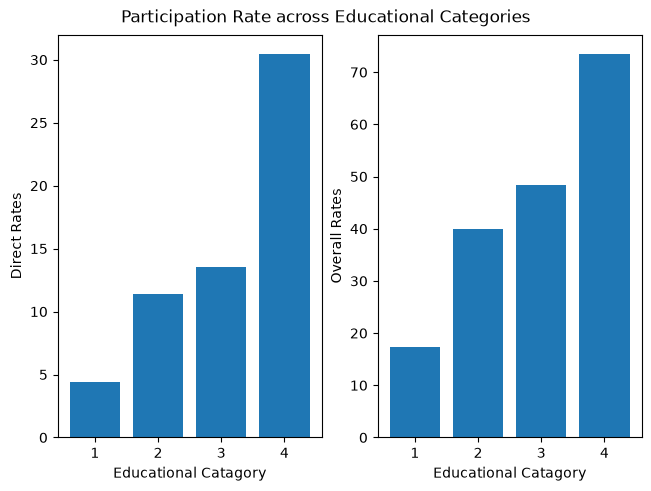

In [24]:
#plotting bar chart
import matplotlib.pyplot as plt

fig,ax= plt.subplots(1,2, layout='constrained')
fig.suptitle('Participation Rate across Educational Categories')
ax[0].bar(range(1,5),direct_list)
ax[0].set_xlabel('Educational Catagory')
ax[0].set_ylabel('Direct Rates')
ax[1].bar(range(1,5), overall_list)
ax[1].set_xlabel('Educational Catagory')
_=ax[1].set_ylabel('Overall Rates')

Both direct and overall rates rise steadily with educational level. Households with a bachelor's degree or higher have a direct rate of 30.5% compared with 4.4% for those without high school (about 7 times highr) and the overall rate is around 4 times higher(73.5% compared with 17.3%). This may reflect that people who are more educated has more financial knowledge or have higher incomes.

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

In [25]:
#Looping over years
df['year'].unique()
direct_year_list=[]
overall_year_list=[]
for year in range(1989,2023,3):
    year_group= df[df['year']==year]
    direct_rate_year= participation_rate(year_group['direct'])
    direct_year_list.append(direct_rate_year)
    overall_rate_year= participation_rate(year_group['overall'])
    overall_year_list.append(overall_rate_year)

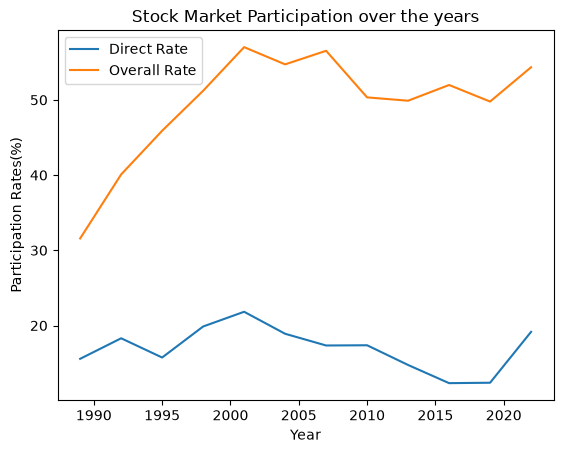

In [26]:
#Creating Line plot
x= range(1989,2023,3)
y1=direct_year_list
y2=overall_year_list
fig, ax=plt.subplots()
ax.plot(x, y1, label= 'Direct Rate')
ax.plot(x,y2, label='Overall Rate')
ax.set_title('Stock Market Participation over the years')
ax.set_xlabel('Year')
ax.set_ylabel('Participation Rates(%)')
_=ax.legend()


In [27]:
direct_change=direct_year_list[-1]-direct_year_list[0]
overall_change=overall_year_list[-1]-overall_year_list[0]
print(f'The changes from 1989 to 2022 in the Direct participation is: {direct_change:.1f} percentage points')
print(f'The changes from 1989 to 2022 in the Overall participation is: {overall_change:.1f} percentage points')

The changes from 1989 to 2022 in the Direct participation is: 3.6 percentage points
The changes from 1989 to 2022 in the Overall participation is: 22.8 percentage points


Overall participation rate rose steeply from 1989 to 2001, then declined gradually before increasing again in 2022, giving a net change of 22.8 percentage points. In contrast, direct participation  changed little over the period, it rose until 2001, declined gradually until 2019 and increased again in 2022, giving a net change of 3.6 percentage points. Although both rates folllowed a similar pattern, peaking in 2001 and rising again in 2022, the much larger increase in overall participation suggests that the growth came mostly from indirect/overall holdings. 

***
## AI-use statement

Students must describe their own use of AI here, or state that they did not use it.

I used Claude (by Anthropic) as AI for understanding some questions and finding errors in my code. Most of the code I wrote myself but for some parts such as missing values (how to use dropna) and the loop in part 3, I was a bit confused so AI gave me hints and partial solution, then slowly I typed in my way and made sure that I understood  what I wrote.